In [1]:
import pandas as pd
import numpy as np
import gzip
import matplotlib.pyplot as plt
import pickle
from scipy.stats import linregress
from scipy.stats import norm
from scipy.stats import fisher_exact
import os
import sys
from datetime import date
from sklearn.metrics import auc, f1_score
import random
from sklearn.decomposition import NMF, non_negative_factorization
import seaborn as sns
import time
from matplotlib.colors import LogNorm, Normalize
from mpl_toolkits.axes_grid1 import axes_grid
import mpl_scatter_density
from matplotlib.colors import LinearSegmentedColormap
import plotly.graph_objects as go
import pyBigWig
from scipy.spatial import distance
from scipy.spatial.distance import pdist, squareform
from sklearn.metrics.pairwise import cosine_similarity
from scipy import sparse
from sklearn.neighbors import NearestNeighbors, KDTree
from statsmodels.stats.contingency_tables import mcnemar
import math

**load data**

In [2]:
#load npz file
added_recon_all_cycles = []
removed_recon_all_cycles = []
added_flat_inds_all_cycles = []
removed_flat_inds_all_cycles = []

for i in range(1, 2):
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/reconstructed_threshold_flip_added_removed_recon_flatinds_to0thresh0.0_to1thresh1.0_cycle'+str(i)+'_CT20220323.npz'
    cycle_np_file = np.load(filename)
    added_recon_all_cycles.append(cycle_np_file['added_recon'])
    removed_recon_all_cycles.append(cycle_np_file['removed_recon'])
    added_flat_inds_all_cycles.append(cycle_np_file['added_flat_inds'])
    removed_flat_inds_all_cycles.append(cycle_np_file['removed_flat_inds'])

In [12]:
cycle0_dhs_arr = np.load('/home/ctrader/Hold/DHS/dat_bin_FDR01_hg38_bool_array.npy')
n_biosamples, n_DHSs = cycle0_dhs_arr.shape

In [3]:
DHS_metadata = pd.read_table('/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_hg38_WM20190703.txt.gz', header=None)

col_names = DHS_metadata.iloc[0]
DHS_metadata = DHS_metadata[1:]
DHS_metadata.columns = col_names
DHS_metadata = DHS_metadata.reset_index()
DHS_metadata[['identifier']] = DHS_metadata[['identifier']].astype(str)
DHS_metadata = DHS_metadata.drop(columns=['index'])
DHS_metadata['mean_signal'] = DHS_metadata['mean_signal'].astype(float)

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (1,2,3,4,5,6,7,8) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [4]:
#loading biosample metadata
tsv_file = open("/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_metadata.tsv")
biosample_df = pd.read_csv(tsv_file, delimiter="\t")

In [7]:
# cycle0_dhs_arr = cycle0_dhs_arr.astype(int)

In [8]:
cycle0_dhs_arr_sparse = sparse.csr_matrix(cycle0_dhs_arr)

In [7]:
#original mixture
fn = gzip.GzipFile('/home/ctrader/Hold/DHS/2018-06-08NC16_NNDSVD_Basis.npy.gz', "r")
cycle0_basis = np.float32(np.load(fn))

In [142]:
#load npz file
mixture_all_cycles = []

#original mixture
fn = gzip.GzipFile('/home/ctrader/Hold/DHS/2018-06-08NC16_NNDSVD_Mixture.npy.gz', "r")
mixture_all_cycles.append(np.float32(np.load(fn)))

for i in range(1, 2):
    print(i)
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/reconstructed_threshold_flip_booldhsarr_basis_mixture_to0thresh0.0_to1thresh1.0_cycle'+str(i)+'_CT20220323.npz'
    cycle_np_file = np.load(filename)
    mixture_all_cycles.append(cycle_np_file['new_decomp_mixture'])

mixture_all_cycles = np.array(mixture_all_cycles)

1


In [143]:
mixture_all_cycles_top_comp = np.argmax(mixture_all_cycles, axis=1)

**jaccard distance for original matrix**

In [10]:
cycle0_biosample_jdistances = pdist(cycle0_dhs_arr, metric='jaccard')
cycle0_biosample_jdistances = squareform(cycle0_biosample_jdistances)

In [13]:
filename = '/home/ctrader/Hold/NMF/DHS/biosample_neighbors/original_DHS_matrix_biosample_jaccarddistances_CT20220331.npy'
np.save(filename, cycle0_biosample_jdistances)

In [5]:
filename = '/home/ctrader/Hold/NMF/DHS/biosample_neighbors/original_DHS_matrix_biosample_jaccarddistances_CT20220331.npy'
cycle0_biosample_jdistances = np.load(filename)

**jaccard distance for basis matrix**

In [193]:
cycle0_biosample_NMF_jdistances = pdist(cycle0_basis, metric='jaccard')
cycle0_biosample_NMF_jdistances = squareform(cycle0_biosample_NMF_jdistances)

In [194]:
filename = '/home/ctrader/Hold/NMF/DHS/biosample_neighbors/original_DHS_matrix_biosample_NMFjaccarddistances_CT20220331.npy'
np.save(filename, cycle0_biosample_NMF_jdistances)

In [10]:
# filename = '/home/ctrader/Hold/NMF/DHS/biosample_neighbors/original_DHS_matrix_biosample_NMFjaccarddistances_CT20220331.npy'
# cycle0_biosample_NMF_jdistances = np.load(filename)

**Cosine similarity for original matrix**

In [41]:
cycle0_biosample_cosinesim = cosine_similarity(cycle0_dhs_arr_sparse)

In [54]:
filename = '/home/ctrader/Hold/NMF/DHS/biosample_neighbors/original_DHS_matrix_biosample_cosinesimilarity_CT20220331.npy'
np.save(filename, cycle0_biosample_cosinesim)

In [6]:
filename = '/home/ctrader/Hold/NMF/DHS/biosample_neighbors/original_DHS_matrix_biosample_cosinesimilarity_CT20220331.npy'
cycle0_biosample_cosinesim = np.load(filename)

**Cosine similarity for basis matrix**

In [191]:
cycle0_biosample_NMF_cosinesim = cosine_similarity(cycle0_basis)

In [192]:
filename = '/home/ctrader/Hold/NMF/DHS/biosample_neighbors/original_DHS_matrix_biosample_NMFcosinesimilarity_CT20220331.npy'
np.save(filename, cycle0_biosample_NMF_cosinesim)

In [7]:
filename = '/home/ctrader/Hold/NMF/DHS/biosample_neighbors/original_DHS_matrix_biosample_NMFcosinesimilarity_CT20220331.npy'
cycle0_biosample_NMF_cosinesim = np.load(filename)

**NMF ordering (as in index browser)**

In [56]:
cycle0_basis_top_comp = np.argmax(cycle0_basis, axis=1)
NMF_ordered_biosamples = np.array([])
for i in range(16):
    comp_biosamples = np.where(cycle0_basis_top_comp == i)[0]
    ordered_biosamples = comp_biosamples[np.argsort(-cycle0_basis[comp_biosamples, i])]
    NMF_ordered_biosamples = np.append(NMF_ordered_biosamples, ordered_biosamples)
NMF_ordered_biosamples = NMF_ordered_biosamples.astype(int)

In [185]:
filename = '/home/ctrader/Hold/NMF/DHS/biosample_neighbors/original_DHS_matrix_biosample_NMFordering_CT20220331.npy'
np.save(filename, NMF_ordered_biosamples)

In [8]:
filename = '/home/ctrader/Hold/NMF/DHS/biosample_neighbors/original_DHS_matrix_biosample_NMFordering_CT20220331.npy'
NMF_ordered_biosamples = np.load(filename)

**NMF ordering official**

In [37]:
comps_for_heatmap_no_spaces = ['Tissue invariant', 'Stromal A', 'Primitive/embryonic', 'Stromal B', 'Lymphoid', 
                               'Renal/cancer', 'Placental/trophoblast', 'Neural', 'Cardiac', 
                               'Organ devel./renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 
                               'Vascular/endothelial', 'Myeloid/erythroid', 'Cancer/epithelial']

rearrangement_order = [6, 4, 14, 8, 11, 13, 2, 7, 12, 1, 3, 5, 15, 10, 9, 0]
for r in rearrangement_order:
    print(comps_for_heatmap_no_spaces[r])

Placental/trophoblast
Lymphoid
Myeloid/erythroid
Cardiac
Musculoskeletal
Vascular/endothelial
Primitive/embryonic
Neural
Digestive
Stromal A
Stromal B
Renal/cancer
Cancer/epithelial
Pulmonary devel.
Organ devel./renal
Tissue invariant


In [93]:
cycle0_basis_tidq = np.copy(cycle0_basis)
cycle0_basis_tidq[:, 0]=0

cycle0_basis_tidq_top_comp = np.argmax(cycle0_basis_tidq, axis=1)
NMF_official_ordered_biosamples = np.array([])
for i in rearrangement_order:
    comp_biosamples = np.where(cycle0_basis_tidq_top_comp == i)[0]
    ordered_biosamples = comp_biosamples[np.argsort(-cycle0_basis_tidq[comp_biosamples, i])]
    NMF_official_ordered_biosamples = np.append(NMF_official_ordered_biosamples, ordered_biosamples)
NMF_official_ordered_biosamples = NMF_official_ordered_biosamples.astype(int)

In [94]:
filename = '/home/ctrader/Hold/NMF/DHS/biosample_neighbors/original_DHS_matrix_biosample_NMFofficialordering_CT20220331.npy'
np.save(filename, NMF_official_ordered_biosamples)

In [9]:
filename = '/home/ctrader/Hold/NMF/DHS/biosample_neighbors/original_DHS_matrix_biosample_NMFofficialordering_CT20220331.npy'
NMF_official_ordered_biosamples = np.load(filename)

**nearest neighbor clustering**

In [4]:
# cycle0_biosample_kdtree = KDTree(cycle0_dhs_arr, leaf_size=20, metric='euclidean')
cycle0_biosample_kdtree = NearestNeighbors(n_neighbors=2, algorithm='kd_tree').fit(cycle0_dhs_arr)
cycle0_biosample_kdtree_neighbors = cycle0_biosample_kdtree.kneighbors_graph(cycle0_dhs_arr).toarray()

In [9]:
filename = '/home/ctrader/Hold/NMF/DHS/biosample_neighbors/original_DHS_matrix_biosample_kdtree2neighbors_CT20220331.npy'
np.save(filename, cycle0_biosample_kdtree_neighbors)

In [10]:
filename = '/home/ctrader/Hold/NMF/DHS/biosample_neighbors/original_DHS_matrix_biosample_kdtree2neighbors_CT20220331.npy'
cycle0_biosample_kdtree_neighbors = np.load(filename)

**NMF nearest neighbor clustering**

In [7]:
cycle0_biosample_NMF_kdtree = NearestNeighbors(n_neighbors=2, algorithm='kd_tree').fit(cycle0_basis)
cycle0_biosample_NMF_kdtree_neighbors = cycle0_biosample_NMF_kdtree.kneighbors_graph(cycle0_basis).toarray()

In [10]:
filename = '/home/ctrader/Hold/NMF/DHS/biosample_neighbors/original_DHS_matrix_biosample_NMFkdtree2neighbors_CT20220331.npy'
np.save(filename, cycle0_biosample_NMF_kdtree_neighbors)

In [11]:
filename = '/home/ctrader/Hold/NMF/DHS/biosample_neighbors/original_DHS_matrix_biosample_NMFkdtree2neighbors_CT20220331.npy'
cycle0_biosample_NMF_kdtree_neighbors = np.load(filename)

**neighbor concordance with flipping**

In [238]:
def neighbor_concordance(metric, flipped_flat_inds, added=True, dhs_arr=cycle0_dhs_arr):
    neighbor_concord = []
    for flat_ind in flipped_flat_inds:
        biosample = flat_ind // n_DHSs
        dhs = flat_ind % n_DHSs
        og_comp = mixture_all_cycles_top_comp[0, dhs]
        new_comp = mixture_all_cycles_top_comp[1, dhs]
        num_biosamples = np.sum(dhs_arr[:, dhs])
        nearest_biosamples = np.argsort(-metric[biosample, :])[:2]
        nearest_biosample = nearest_biosamples[nearest_biosamples!=biosample][0]
        if ((added) & (dhs_arr[nearest_biosample, dhs])):
            neighbor_concord.append([biosample, dhs, nearest_biosample, num_biosamples, True, og_comp, new_comp])
        elif ((~added) & (~dhs_arr[nearest_biosample, dhs])):
            neighbor_concord.append([biosample, dhs, nearest_biosample, num_biosamples, True, og_comp, new_comp])
        else:
            neighbor_concord.append([biosample, dhs, nearest_biosample, num_biosamples, False, og_comp, new_comp])
    neighbor_concord = np.array(neighbor_concord)
    return neighbor_concord

In [239]:
added_concord = []
removed_concord = []
labels = []

In [240]:
#kdtree
cycle0_biosample_kdtree_neighbor_added_concord = neighbor_concordance(cycle0_biosample_kdtree_neighbors, 
                                                                      added_flat_inds_all_cycles[0], 
                                                                      added=True)
print(len(np.where(cycle0_biosample_kdtree_neighbor_added_concord[:, 4])[0]))
added_concord.append(len(np.where(cycle0_biosample_kdtree_neighbor_added_concord[:, 4])[0]))

cycle0_biosample_kdtree_neighbor_removed_concord = neighbor_concordance(cycle0_biosample_kdtree_neighbors, 
                                                                        removed_flat_inds_all_cycles[0], 
                                                                        added=False)
print(len(np.where(cycle0_biosample_kdtree_neighbor_removed_concord[:, 4])[0]))
removed_concord.append(len(np.where(cycle0_biosample_kdtree_neighbor_removed_concord[:, 4])[0]))
labels.append('KD-Tree')

33799
21082


In [241]:
#NMF kdtree
cycle0_biosample_NMF_kdtree_neighbor_added_concord = neighbor_concordance(cycle0_biosample_NMF_kdtree_neighbors, 
                                                                          added_flat_inds_all_cycles[0], 
                                                                          added=True)
print(len(np.where(cycle0_biosample_NMF_kdtree_neighbor_added_concord[:, 4])[0]))
added_concord.append(len(np.where(cycle0_biosample_NMF_kdtree_neighbor_added_concord[:, 4])[0]))

cycle0_biosample_NMF_kdtree_neighbor_removed_concord = neighbor_concordance(cycle0_biosample_NMF_kdtree_neighbors, 
                                                                            removed_flat_inds_all_cycles[0], 
                                                                            added=False)
print(len(np.where(cycle0_biosample_NMF_kdtree_neighbor_removed_concord[:, 4])[0]))
removed_concord.append(len(np.where(cycle0_biosample_NMF_kdtree_neighbor_removed_concord[:, 4])[0]))
labels.append('NMF KD-Tree')

39985
21625


In [242]:
cycle0_biosample_jsimilarity = 1 - cycle0_biosample_jdistances
#jaccard similarities
cycle0_biosample_jsimilarity_added_concord = neighbor_concordance(cycle0_biosample_jsimilarity, 
                                                                  added_flat_inds_all_cycles[0], 
                                                                  added=True)
print(len(np.where(cycle0_biosample_jsimilarity_added_concord[:, 4])[0]))
added_concord.append(len(np.where(cycle0_biosample_jsimilarity_added_concord[:, 4])[0]))

cycle0_biosample_jsimilarity_removed_concord = neighbor_concordance(cycle0_biosample_jsimilarity, 
                                                                    removed_flat_inds_all_cycles[0], 
                                                                    added=False)
print(len(np.where(cycle0_biosample_jsimilarity_removed_concord[:, 4])[0]))
removed_concord.append(len(np.where(cycle0_biosample_jsimilarity_removed_concord[:, 4])[0]))
labels.append('Jaccard Similarity')

35522
20836


In [243]:
#cosine similarities
cycle0_biosample_cosine_added_concord = neighbor_concordance(cycle0_biosample_cosinesim, 
                                                             added_flat_inds_all_cycles[0], 
                                                             added=True)
print(len(np.where(cycle0_biosample_cosine_added_concord[:, 4])[0]))
added_concord.append(len(np.where(cycle0_biosample_cosine_added_concord[:, 4])[0]))

cycle0_biosample_cosine_removed_concord = neighbor_concordance(cycle0_biosample_cosinesim, 
                                                               removed_flat_inds_all_cycles[0], 
                                                               added=False)
print(len(np.where(cycle0_biosample_cosine_removed_concord[:, 4])[0]))
removed_concord.append(len(np.where(cycle0_biosample_cosine_removed_concord[:, 4])[0]))
labels.append('Cosine Similarity')

35249
20803


In [244]:
#NMF cosine similarities
cycle0_biosample_NMF_cosine_added_concord = neighbor_concordance(cycle0_biosample_NMF_cosinesim, 
                                                                 added_flat_inds_all_cycles[0], 
                                                                 added=True)
print(len(np.where(cycle0_biosample_NMF_cosine_added_concord[:, 4])[0]))
added_concord.append(len(np.where(cycle0_biosample_NMF_cosine_added_concord[:, 4])[0]))

cycle0_biosample_NMF_cosine_removed_concord = neighbor_concordance(cycle0_biosample_NMF_cosinesim, 
                                                                   removed_flat_inds_all_cycles[0], 
                                                                   added=False)
print(len(np.where(cycle0_biosample_NMF_cosine_removed_concord[:, 4])[0]))
removed_concord.append(len(np.where(cycle0_biosample_NMF_cosine_removed_concord[:, 4])[0]))
labels.append('NMF Cosine Similarity')

38690
21602


In [245]:
def neighbor_concordance_NMForderonly(flipped_flat_inds, 
                                      metric=NMF_ordered_biosamples, 
                                      added=True, 
                                      dhs_arr=cycle0_dhs_arr):
    neighbor_concord = []
    for flat_ind in flipped_flat_inds:
        biosample = flat_ind // n_DHSs
        dhs = flat_ind % n_DHSs
        og_comp = mixture_all_cycles_top_comp[0, dhs]
        new_comp = mixture_all_cycles_top_comp[1, dhs]
        num_biosamples = np.sum(dhs_arr[:, dhs])
        biosample_loc = np.where(metric==biosample)[0][0]
        if ((biosample_loc!=0) & (biosample_loc!=732)):
            neighbors_loc = [biosample_loc+1, biosample_loc-1]
        elif biosample_loc==0:
            neighbors_loc = [732, 1]
        else:
            neighbors_loc = [731, 0]
        neighbors = metric[neighbors_loc]
        local_neighbors = []
        for nearest_biosample in neighbors:
            if ((added) & (dhs_arr[nearest_biosample, dhs])):
                local_neighbors.extend([biosample, dhs, nearest_biosample, num_biosamples, True, og_comp, new_comp])
            elif ((~added) & (~dhs_arr[nearest_biosample, dhs])):
                local_neighbors.extend([biosample, dhs, nearest_biosample, num_biosamples, True, og_comp, new_comp])
            else:
                local_neighbors.extend([biosample, dhs, nearest_biosample, num_biosamples, False, og_comp, new_comp])
        neighbor_concord.append(local_neighbors)
    neighbor_concord = np.array(neighbor_concord)
    return neighbor_concord

In [246]:
#NMF order
cycle0_biosample_NMF_ordered_added_concord = neighbor_concordance_NMForderonly(added_flat_inds_all_cycles[0], 
                                                                               metric=NMF_ordered_biosamples, 
                                                                               added=True)

print(len(np.where((cycle0_biosample_NMF_ordered_added_concord[:, 4]) | (cycle0_biosample_NMF_ordered_added_concord[:, 11]))[0]))
added_concord.append(len(np.where((cycle0_biosample_NMF_ordered_added_concord[:, 4]) | (cycle0_biosample_NMF_ordered_added_concord[:, 11]))[0]))

cycle0_biosample_NMF_ordered_removed_concord = neighbor_concordance_NMForderonly(removed_flat_inds_all_cycles[0], 
                                                                                 metric=NMF_ordered_biosamples, 
                                                                                 added=False)

print(len(np.where((cycle0_biosample_NMF_ordered_removed_concord[:, 4]) | (cycle0_biosample_NMF_ordered_removed_concord[:, 11]))[0]))
removed_concord.append(len(np.where((cycle0_biosample_NMF_ordered_removed_concord[:, 4]) | (cycle0_biosample_NMF_ordered_removed_concord[:, 11]))[0]))
labels.append('NMF Ordered')

45358
22426


In [247]:
#NMF paper order
cycle0_biosample_NMF_official_ordered_added_concord = neighbor_concordance_NMForderonly(added_flat_inds_all_cycles[0], 
                                                                                        metric=NMF_official_ordered_biosamples, 
                                                                                        added=True)

print(len(np.where((cycle0_biosample_NMF_official_ordered_added_concord[:, 4]) | (cycle0_biosample_NMF_official_ordered_added_concord[:, 11]))[0]))
added_concord.append(len(np.where((cycle0_biosample_NMF_official_ordered_added_concord[:, 4]) | (cycle0_biosample_NMF_official_ordered_added_concord[:, 11]))[0]))

cycle0_biosample_NMF_official_ordered_removed_concord = neighbor_concordance_NMForderonly(removed_flat_inds_all_cycles[0], 
                                                                                          metric=NMF_official_ordered_biosamples, 
                                                                                          added=False)
print(len(np.where((cycle0_biosample_NMF_official_ordered_removed_concord[:, 4]) | (cycle0_biosample_NMF_official_ordered_removed_concord[:, 11]))[0]))
removed_concord.append(len(np.where((cycle0_biosample_NMF_official_ordered_removed_concord[:, 4]) | (cycle0_biosample_NMF_official_ordered_removed_concord[:, 11]))[0]))
labels.append('NMF Paper Ordered')

45368
22431


In [248]:
def random_concordance(flipped_flat_inds, added=True, dhs_arr=cycle0_dhs_arr):
    neighbor_concord = []
    for flat_ind in flipped_flat_inds:
        biosample = flat_ind // n_DHSs
        dhs = flat_ind % n_DHSs
        og_comp = mixture_all_cycles_top_comp[0, dhs]
        new_comp = mixture_all_cycles_top_comp[1, dhs]
        num_biosamples = np.sum(dhs_arr[:, dhs])
        nearest_biosample = random.randrange(733)
        while nearest_biosample == biosample:
            nearest_biosample = random.randrange(733)
        if ((added) & (dhs_arr[nearest_biosample, dhs])):
            neighbor_concord.append([biosample, dhs, nearest_biosample, num_biosamples, True, og_comp, new_comp])
        elif ((~added) & (~dhs_arr[nearest_biosample, dhs])):
            neighbor_concord.append([biosample, dhs, nearest_biosample, num_biosamples, True, og_comp, new_comp])
        else:
            neighbor_concord.append([biosample, dhs, nearest_biosample, num_biosamples, False, og_comp, new_comp])
    neighbor_concord = np.array(neighbor_concord)
    return neighbor_concord

In [249]:
#random concordance
cycle0_biosample_random_added_concord = random_concordance(added_flat_inds_all_cycles[0], 
                                                             added=True)

print(len(np.where(cycle0_biosample_random_added_concord[:, 4])[0]))
added_concord.append(len(np.where(cycle0_biosample_random_added_concord[:, 4])[0]))

cycle0_biosample_random_removed_concord = random_concordance(removed_flat_inds_all_cycles[0], 
                                                               added=False)

print(len(np.where(cycle0_biosample_random_removed_concord[:, 4])[0]))
removed_concord.append(len(np.where(cycle0_biosample_random_removed_concord[:, 4])[0]))

labels.append('Random')

15972
20865


In [250]:
print(len(added_flat_inds_all_cycles[0]))
print(len(removed_flat_inds_all_cycles[0]))

46842
22450


In [251]:
added_concord = np.array(added_concord)
removed_concord = np.array(removed_concord)

added_concord_per = added_concord/len(added_flat_inds_all_cycles[0])*100
removed_concord_per = removed_concord/len(removed_flat_inds_all_cycles[0])*100

In [252]:
# positive_baseline = np.sum(cycle0_dhs_arr)/(n_DHSs*733)
# negative_baseline = 1 - positive_baseline

Text(0.5, 1.0, 'Nearest Biosample Neighbor Concordance for Flipped Calls\nReconstruction Threshold = 0.0/1.0')

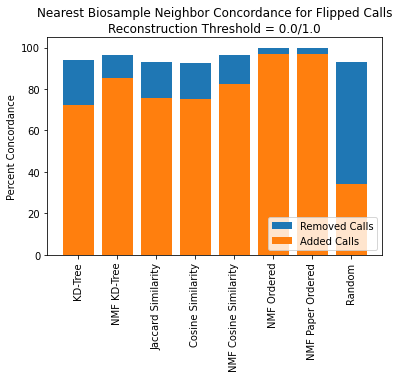

In [253]:
fig = plt.figure()
fig.patch.set_facecolor('white')

plt.bar(np.arange(len(removed_concord_per)), removed_concord_per)#points=1000
plt.bar(np.arange(len(added_concord_per)), added_concord_per)#points=1000
# plt.ylim([0, 6])
# plt.yticks(np.arange(7))


plt.xticks(np.arange(len(labels)), labels, rotation=90)
plt.legend(['Removed Calls', 'Added Calls'], loc='lower right')
plt.ylabel('Percent Concordance')
plt.title('Nearest Biosample Neighbor Concordance for Flipped Calls\nReconstruction Threshold = 0.0/1.0')

Text(0.5, 1.0, 'Nearest Biosample Neighbor Concordance for Flipped Calls')

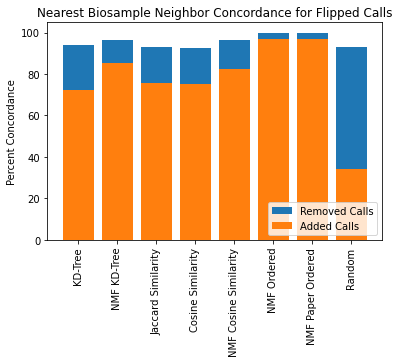

In [254]:
fig = plt.figure()
fig.patch.set_facecolor('white')

plt.bar(np.arange(len(removed_concord_per)), removed_concord_per)#points=1000
plt.bar(np.arange(len(added_concord_per)), added_concord_per)#points=1000
# plt.ylim([0, 6])
# plt.yticks(np.arange(7))


plt.xticks(np.arange(len(labels)), labels, rotation=90)
plt.legend(['Removed Calls', 'Added Calls'], loc='lower right')
plt.ylabel('Percent Concordance')
plt.title('Nearest Biosample Neighbor Concordance for Flipped Calls')

**Contigency Tables**

In [255]:
cycle0_biosample_kdtree_neighbor_addedremoved_concord = np.append(cycle0_biosample_kdtree_neighbor_added_concord, 
                                                                  cycle0_biosample_kdtree_neighbor_removed_concord, 0)

cycle0_biosample_NMF_kdtree_neighbor_addedremoved_concord = np.append(cycle0_biosample_NMF_kdtree_neighbor_added_concord, 
                                                                      cycle0_biosample_NMF_kdtree_neighbor_removed_concord, 0)

cycle0_biosample_jsimilarity_addedremoved_concord = np.append(cycle0_biosample_jsimilarity_added_concord, 
                                                              cycle0_biosample_jsimilarity_removed_concord, 0)

cycle0_biosample_cosine_addedremoved_concord = np.append(cycle0_biosample_cosine_added_concord, 
                                                         cycle0_biosample_cosine_removed_concord, 0)

cycle0_biosample_NMF_cosine_addedremoved_concord = np.append(cycle0_biosample_NMF_cosine_added_concord, 
                                                             cycle0_biosample_NMF_cosine_removed_concord, 0)

cycle0_biosample_NMF_ordered_addedremoved_concord = np.append(cycle0_biosample_NMF_ordered_added_concord,
                                                              cycle0_biosample_NMF_ordered_removed_concord, 0)
cycle0_biosample_NMF_ordered_addedremoved_concord_single = np.ceil((cycle0_biosample_NMF_ordered_addedremoved_concord[:, 4] + 
                                                                    cycle0_biosample_NMF_ordered_addedremoved_concord[:, 11])/2).astype(int)
cycle0_biosample_NMF_ordered_addedremoved_concord_single = np.reshape(cycle0_biosample_NMF_ordered_addedremoved_concord_single, 
                                                                     (len(cycle0_biosample_NMF_ordered_addedremoved_concord_single), 1))
cycle0_biosample_NMF_ordered_addedremoved_concord = np.append(cycle0_biosample_NMF_ordered_addedremoved_concord, 
                                                              cycle0_biosample_NMF_ordered_addedremoved_concord_single, 
                                                              axis=1)


cycle0_biosample_NMF_official_ordered_addedremoved_concord = np.append(cycle0_biosample_NMF_official_ordered_added_concord,
                                                                       cycle0_biosample_NMF_official_ordered_removed_concord, 0)
cycle0_biosample_NMF_official_ordered_addedremoved_concord_single = np.ceil((cycle0_biosample_NMF_official_ordered_addedremoved_concord[:, 4] + 
                                                                             cycle0_biosample_NMF_official_ordered_addedremoved_concord[:, 11])/2).astype(int)
cycle0_biosample_NMF_official_ordered_addedremoved_concord_single = np.reshape(cycle0_biosample_NMF_official_ordered_addedremoved_concord_single, 
                                                                               (len(cycle0_biosample_NMF_official_ordered_addedremoved_concord_single), 1))
cycle0_biosample_NMF_official_ordered_addedremoved_concord = np.append(cycle0_biosample_NMF_official_ordered_addedremoved_concord, 
                                                                       cycle0_biosample_NMF_official_ordered_addedremoved_concord_single, 
                                                                       axis=1)


cycle0_biosample_random_addedremoved_concord = np.append(cycle0_biosample_random_added_concord, 
                                                         cycle0_biosample_random_removed_concord, 0)

In [256]:
# cycle0_biosample_kdtree_conting = np.zeros((2, 2)).astype(int)
# for i, j in zip(cycle0_biosample_kdtree_neighbor_addedremoved_concord[:, 4], 
#                 cycle0_biosample_random_addedremoved_concord[:, 4]):
#     i = np.abs(i-1)
#     j = np.abs(j-1)
#     cycle0_biosample_kdtree_conting[i, j]+=1
    

# cycle0_biosample_NMF_kdtree_conting = np.zeros((2, 2)).astype(int)
# for i, j in zip(cycle0_biosample_NMF_kdtree_neighbor_addedremoved_concord[:, 4], 
#                 cycle0_biosample_random_addedremoved_concord[:, 4]):
#     i = np.abs(i-1)
#     j = np.abs(j-1)
#     cycle0_biosample_NMF_kdtree_conting[i, j]+=1

    
# cycle0_biosample_jsimilarity_conting = np.zeros((2, 2)).astype(int)
# for i, j in zip(cycle0_biosample_jsimilarity_addedremoved_concord[:, 4], 
#                 cycle0_biosample_random_addedremoved_concord[:, 4]):
#     i = np.abs(i-1)
#     j = np.abs(j-1)
#     cycle0_biosample_jsimilarity_conting[i, j]+=1
    
    
# cycle0_biosample_cosine_conting = np.zeros((2, 2)).astype(int)
# for i, j in zip(cycle0_biosample_cosine_addedremoved_concord[:, 4], 
#                 cycle0_biosample_random_addedremoved_concord[:, 4]):
#     i = np.abs(i-1)
#     j = np.abs(j-1)
#     cycle0_biosample_cosine_conting[i, j]+=1
    
    
# cycle0_biosample_NMF_cosine_conting = np.zeros((2, 2)).astype(int)
# for i, j in zip(cycle0_biosample_NMF_cosine_addedremoved_concord[:, 4], 
#                 cycle0_biosample_random_addedremoved_concord[:, 4]):
#     i = np.abs(i-1)
#     j = np.abs(j-1)
#     cycle0_biosample_NMF_cosine_conting[i, j]+=1
    

# cycle0_biosample_NMF_ordered_conting = np.zeros((2, 2)).astype(int)
# for i, j in zip(cycle0_biosample_NMF_ordered_addedremoved_concord[:, 10], 
#                 cycle0_biosample_random_addedremoved_concord[:, 4]):
#     i = np.abs(i-1)
#     j = np.abs(j-1)
#     cycle0_biosample_NMF_ordered_conting[i, j]+=1
    
    
# cycle0_biosample_NMF_official_ordered_conting = np.zeros((2, 2)).astype(int)
# for i, j in zip(cycle0_biosample_NMF_official_ordered_addedremoved_concord[:, 10], 
#                 cycle0_biosample_random_addedremoved_concord[:, 4]):
#     i = np.abs(i-1)
#     j = np.abs(j-1)
#     cycle0_biosample_NMF_official_ordered_conting[i, j]+=1

In [257]:
cycle0_biosample_NMF_ordered_addedremoved_concord.shape

(69292, 15)

/tmp/ipykernel_87819/3321516766.py:33: RuntimeWarning: invalid value encountered in true_divide
  concord_biosamples_bin_heights = concord_biosamples_bin_heights / norm
/tmp/ipykernel_87819/3321516766.py:34: RuntimeWarning: invalid value encountered in true_divide
  not_concord_biosamples_bin_heights = not_concord_biosamples_bin_heights / norm


Text(0.5, 1.0, 'Nearest Neighbor Concordance and Total Number of Positive Biosamples for Flipped Calls\nReconstruction Threshold = 0.0/1.0')

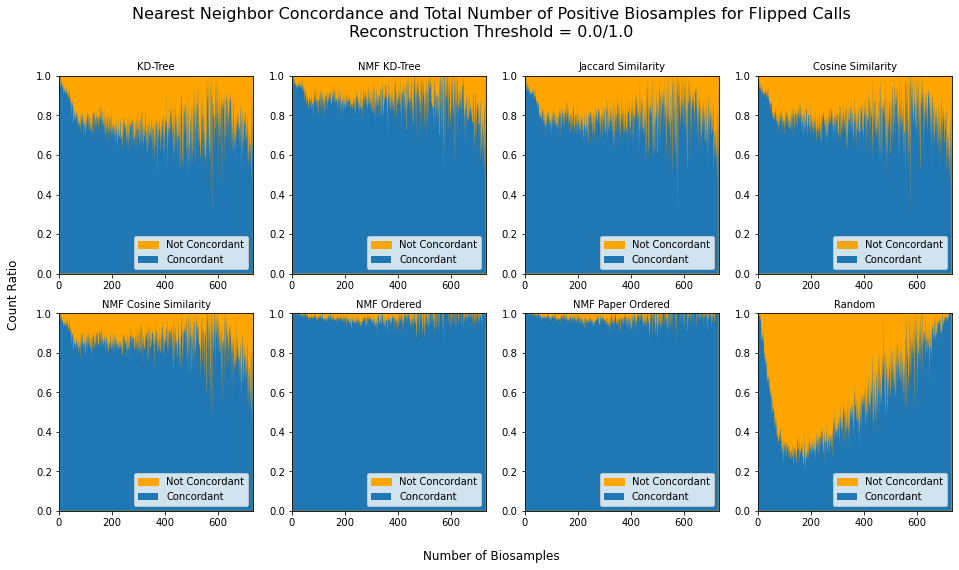

In [326]:
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(16,8))
# plt.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=0.3, hspace=None)
fig.patch.set_facecolor('white')
# fig.tight_layout()

axes = axes.ravel()

for ax, result, ind in zip(axes, [cycle0_biosample_kdtree_neighbor_addedremoved_concord,
                                  cycle0_biosample_NMF_kdtree_neighbor_addedremoved_concord,
                                  cycle0_biosample_jsimilarity_addedremoved_concord,
                                  cycle0_biosample_cosine_addedremoved_concord,
                                  cycle0_biosample_NMF_cosine_addedremoved_concord,
                                  cycle0_biosample_NMF_ordered_addedremoved_concord,
                                  cycle0_biosample_NMF_official_ordered_addedremoved_concord,
                                  cycle0_biosample_random_addedremoved_concord],
                          range(len(axes))):
    
    if result.shape == (69292, 15):
        concord_inds = np.where(result[:, 14]==1)
        not_concord_inds = np.where(result[:, 14]==0)
    else:
        concord_inds = np.where(result[:, 4]==1)
        not_concord_inds = np.where(result[:, 4]==0)
    concord_biosamples = result[concord_inds, 3]
    not_concord_biosamples = result[not_concord_inds, 3]
    
    concord_biosamples_bin_heights = np.array([])
    not_concord_biosamples_bin_heights = np.array([])
    for i in range(1, 733):
        concord_biosamples_bin_heights = np.append(concord_biosamples_bin_heights, len(concord_biosamples[concord_biosamples==i]))
        not_concord_biosamples_bin_heights = np.append(not_concord_biosamples_bin_heights, len(not_concord_biosamples[not_concord_biosamples==i]))
    norm = concord_biosamples_bin_heights + not_concord_biosamples_bin_heights
    concord_biosamples_bin_heights = concord_biosamples_bin_heights / norm
    not_concord_biosamples_bin_heights = not_concord_biosamples_bin_heights / norm
    
#     df=pd.DataFrame([concord_biosamples.flatten(), not_concord_biosamples.flatten()], index=['Concordant', 'Not Concordant']).transpose()
    
#     t1 = sns.histplot(data=df, ax=ax, kde=True, stat='probability')
    axes[ind].fill_between(np.arange(1, 733), not_concord_biosamples_bin_heights+concord_biosamples_bin_heights, color='orange')
    axes[ind].fill_between(np.arange(1, 733), concord_biosamples_bin_heights)
    axes[ind].set_title(labels[ind], fontsize=10)
    ax.set_ylabel(None)
    ax.set_ylim([0, 1])
    ax.set_xlim([0, 733])
    ax.legend(['Not Concordant', 'Concordant'], loc='lower right')
#     axes[ind+2].set_title('Cycle %s Basis' %(ind), fontsize=10)

# axes[0].set_ylabel('Number of DHSs', fontsize=12)
# axes[2].set_ylabel('Number of Biosamples', fontsize=12)
fig.text(0.08, 0.5, 'Count Ratio', va='center', rotation='vertical', fontsize=12)
fig.text(0.5, 0.04, 'Number of Biosamples', ha='center', fontsize=12)
plt.suptitle('Nearest Neighbor Concordance and Total Number of Positive Biosamples for Flipped Calls\nReconstruction Threshold = 0.0/1.0', fontsize=16, x=0.5, y=1.0)

/tmp/ipykernel_87819/4064073873.py:33: RuntimeWarning: invalid value encountered in true_divide
  concord_biosamples_bin_heights = concord_biosamples_bin_heights / norm
/tmp/ipykernel_87819/4064073873.py:34: RuntimeWarning: invalid value encountered in true_divide
  not_concord_biosamples_bin_heights = not_concord_biosamples_bin_heights / norm


Text(0.5, 1.0, 'Nearest Neighbor Concordance and Total Number\nof Positive Biosamples for Flipped Calls')

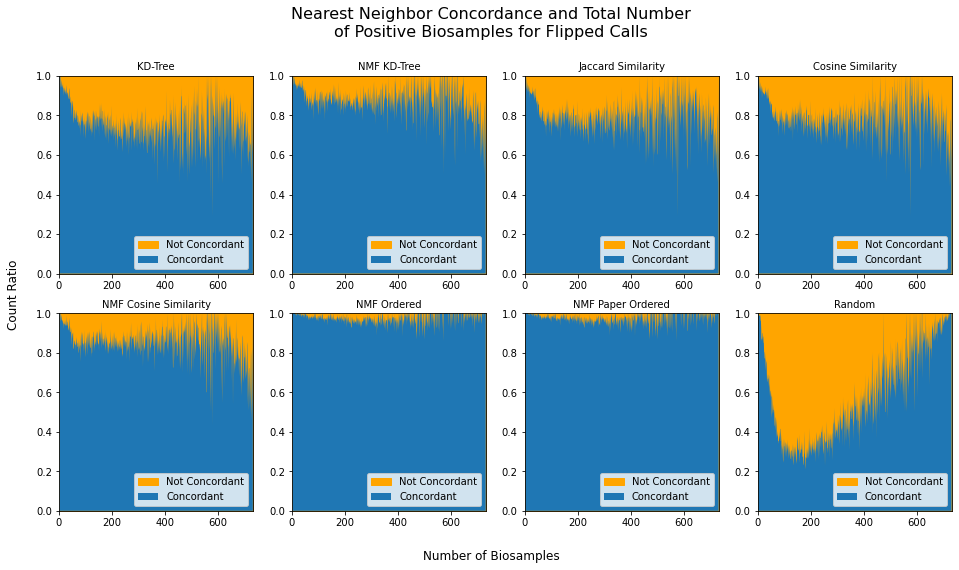

In [325]:
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(16,8))
# plt.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=0.3, hspace=None)
fig.patch.set_facecolor('white')
# fig.tight_layout()

axes = axes.ravel()

for ax, result, ind in zip(axes, [cycle0_biosample_kdtree_neighbor_addedremoved_concord,
                                  cycle0_biosample_NMF_kdtree_neighbor_addedremoved_concord,
                                  cycle0_biosample_jsimilarity_addedremoved_concord,
                                  cycle0_biosample_cosine_addedremoved_concord,
                                  cycle0_biosample_NMF_cosine_addedremoved_concord,
                                  cycle0_biosample_NMF_ordered_addedremoved_concord,
                                  cycle0_biosample_NMF_official_ordered_addedremoved_concord,
                                  cycle0_biosample_random_addedremoved_concord],
                          range(len(axes))):
    
    if result.shape == (69292, 15):
        concord_inds = np.where(result[:, 14]==1)
        not_concord_inds = np.where(result[:, 14]==0)
    else:
        concord_inds = np.where(result[:, 4]==1)
        not_concord_inds = np.where(result[:, 4]==0)
    concord_biosamples = result[concord_inds, 3]
    not_concord_biosamples = result[not_concord_inds, 3]
    
    concord_biosamples_bin_heights = np.array([])
    not_concord_biosamples_bin_heights = np.array([])
    for i in range(1, 733):
        concord_biosamples_bin_heights = np.append(concord_biosamples_bin_heights, len(concord_biosamples[concord_biosamples==i]))
        not_concord_biosamples_bin_heights = np.append(not_concord_biosamples_bin_heights, len(not_concord_biosamples[not_concord_biosamples==i]))
    norm = concord_biosamples_bin_heights + not_concord_biosamples_bin_heights
    concord_biosamples_bin_heights = concord_biosamples_bin_heights / norm
    not_concord_biosamples_bin_heights = not_concord_biosamples_bin_heights / norm
    
#     df=pd.DataFrame([concord_biosamples.flatten(), not_concord_biosamples.flatten()], index=['Concordant', 'Not Concordant']).transpose()
    
#     t1 = sns.histplot(data=df, ax=ax, kde=True, stat='probability')
    axes[ind].fill_between(np.arange(1, 733), not_concord_biosamples_bin_heights+concord_biosamples_bin_heights, color='orange')
    axes[ind].fill_between(np.arange(1, 733), concord_biosamples_bin_heights)
    axes[ind].set_title(labels[ind], fontsize=10)
    ax.set_ylabel(None)
    ax.set_ylim([0, 1])
    ax.set_xlim([0, 733])
    ax.legend(['Not Concordant', 'Concordant'], loc='lower right')
#     axes[ind+2].set_title('Cycle %s Basis' %(ind), fontsize=10)

# axes[0].set_ylabel('Number of DHSs', fontsize=12)
# axes[2].set_ylabel('Number of Biosamples', fontsize=12)
fig.text(0.08, 0.5, 'Count Ratio', va='center', rotation='vertical', fontsize=12)
fig.text(0.5, 0.04, 'Number of Biosamples', ha='center', fontsize=12)
plt.suptitle('Nearest Neighbor Concordance and Total Number\nof Positive Biosamples for Flipped Calls', fontsize=16, x=0.5, y=1.0)

In [261]:
#significance binned by number of biosamples
cycle0_biosample_metric_v_random_concord_pvals = []
for result in [cycle0_biosample_kdtree_neighbor_addedremoved_concord,
               cycle0_biosample_NMF_kdtree_neighbor_addedremoved_concord,
               cycle0_biosample_jsimilarity_addedremoved_concord,
               cycle0_biosample_cosine_addedremoved_concord,
               cycle0_biosample_NMF_cosine_addedremoved_concord,
               cycle0_biosample_NMF_ordered_addedremoved_concord,
               cycle0_biosample_NMF_official_ordered_addedremoved_concord,
               cycle0_biosample_random_addedremoved_concord]:
    
    result_pval = np.array([])
    for i in range(1, 734):
        numbio_inds = np.where(result[:, 3]==i)[0]
        if result.shape == (69292, 15):
            numbio_specific_result = result[numbio_inds, -1]
        else:
            numbio_specific_result = result[numbio_inds, -3]
        numbio_specific_random = cycle0_biosample_random_addedremoved_concord[numbio_inds, -3]
        
#         contingency = np.zeros((2, 2)).astype(int)
        
        concord_in_both = len(np.arange(len(numbio_specific_random))[((numbio_specific_result==1) & 
                                                                      (numbio_specific_random==1))])
        concord_in_result_only = len(np.arange(len(numbio_specific_random))[((numbio_specific_result==1) & 
                                                                             (numbio_specific_random==0))])
        concord_in_random_only = len(np.arange(len(numbio_specific_random))[((numbio_specific_result==0) & 
                                                                             (numbio_specific_random==1))])
        concord_in_neither = len(np.arange(len(numbio_specific_random))[((numbio_specific_result==0) & 
                                                                         (numbio_specific_random==0))])
        contingency = np.array([[concord_in_both, concord_in_result_only], 
                                [concord_in_random_only, concord_in_neither]])
        if np.min(contingency) < 25:
            pval = mcnemar(contingency, exact=True).pvalue
        else:
            pval = mcnemar(contingency, exact=False, correction=True).pvalue
        result_pval = np.append(result_pval, pval)
    cycle0_biosample_metric_v_random_concord_pvals.append(result_pval)
cycle0_biosample_metric_v_random_concord_pvals = np.array(cycle0_biosample_metric_v_random_concord_pvals)

In [262]:
np.max(-np.log10(cycle0_biosample_metric_v_random_concord_pvals))

49.97097928022088

Text(0.5, 0.97, 'Significance of Flipped Call Nearest Neighbor Concordance\nCompared to Random Per Total Number of Biosamples')

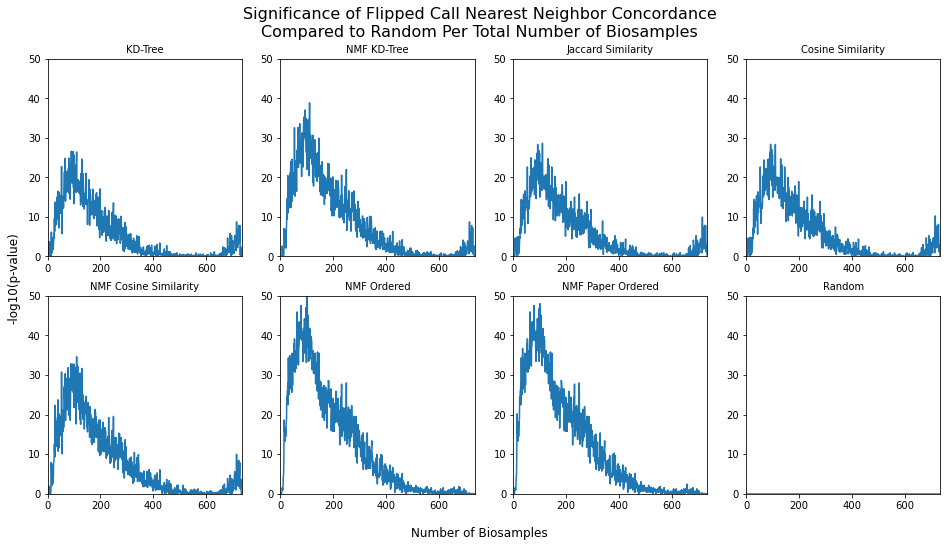

In [263]:
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(16,8))
# plt.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=0.3, hspace=None)
fig.patch.set_facecolor('white')
# fig.tight_layout()

axes = axes.ravel()

for ax, ind in zip(axes, range(len(axes))):
    ax.plot(np.arange(1, 734), -np.log10(cycle0_biosample_metric_v_random_concord_pvals[ind]))
    ax.set_ylim([0, 50])
    ax.set_title(labels[ind], fontsize=10)
    ax.set_xlim([0, 733])
    
fig.text(0.09, 0.5, '-log10(p-value)', va='center', rotation='vertical', fontsize=12)
fig.text(0.5, 0.05, 'Number of Biosamples', ha='center', fontsize=12)
plt.suptitle('Significance of Flipped Call Nearest Neighbor Concordance\nCompared to Random Per Total Number of Biosamples', fontsize=16, x=0.5, y=0.97)

In [309]:
inds_for_comp = np.where((cycle0_biosample_random_addedremoved_concord[:, -2]==10) & 
                         (cycle0_biosample_random_addedremoved_concord[:, -1]==3))[0]
inds_for_comp

array([ 4033,  5056,  8679, 18725, 18727, 26359, 28144, 34371, 39803,
       44091])

In [277]:
#significance binned by components
cycle0_biosample_metric_v_random_concord_pvals_by_comp = []
for result in [cycle0_biosample_kdtree_neighbor_addedremoved_concord,
               cycle0_biosample_NMF_kdtree_neighbor_addedremoved_concord,
               cycle0_biosample_jsimilarity_addedremoved_concord,
               cycle0_biosample_cosine_addedremoved_concord,
               cycle0_biosample_NMF_cosine_addedremoved_concord,
               cycle0_biosample_NMF_ordered_addedremoved_concord,
               cycle0_biosample_NMF_official_ordered_addedremoved_concord,
               cycle0_biosample_random_addedremoved_concord]:
    
    result_pval = np.zeros((16,16), dtype=float)
    for original_comp in range(16):
        for new_comp in range(16):
            inds_for_comp = np.where((cycle0_biosample_random_addedremoved_concord[:, -2]==original_comp) & 
                                     (cycle0_biosample_random_addedremoved_concord[:, -1]==new_comp))[0]
            
            if result.shape == (69292, 15):
                comp_specific_result = result[inds_for_comp, -1]
            else:
                comp_specific_result = result[inds_for_comp, -3]
            comp_specific_random = cycle0_biosample_random_addedremoved_concord[inds_for_comp, -3]
        
            concord_in_both = len(np.arange(len(comp_specific_random))[((comp_specific_result==1) & 
                                                                        (comp_specific_random==1))])
            concord_in_result_only = len(np.arange(len(comp_specific_random))[((comp_specific_result==1) & 
                                                                               (comp_specific_random==0))])
            concord_in_random_only = len(np.arange(len(comp_specific_random))[((comp_specific_result==0) & 
                                                                               (comp_specific_random==1))])
            concord_in_neither = len(np.arange(len(comp_specific_random))[((comp_specific_result==0) & 
                                                                           (comp_specific_random==0))])
            contingency = np.array([[concord_in_both, concord_in_result_only], 
                                    [concord_in_random_only, concord_in_neither]])
            if np.min(contingency) < 25:
                pval = mcnemar(contingency, exact=True).pvalue
            else:
                pval = mcnemar(contingency, exact=False, correction=True).pvalue
            result_pval[new_comp, original_comp] = pval
            
            
            
    cycle0_biosample_metric_v_random_concord_pvals_by_comp.append(result_pval)
cycle0_biosample_metric_v_random_concord_pvals_by_comp = np.array(cycle0_biosample_metric_v_random_concord_pvals_by_comp)

Text(0.5, 0.97, 'Significance of Flipped Call Nearest Neighbor Concordance\nCompared to Random Per Top Component')

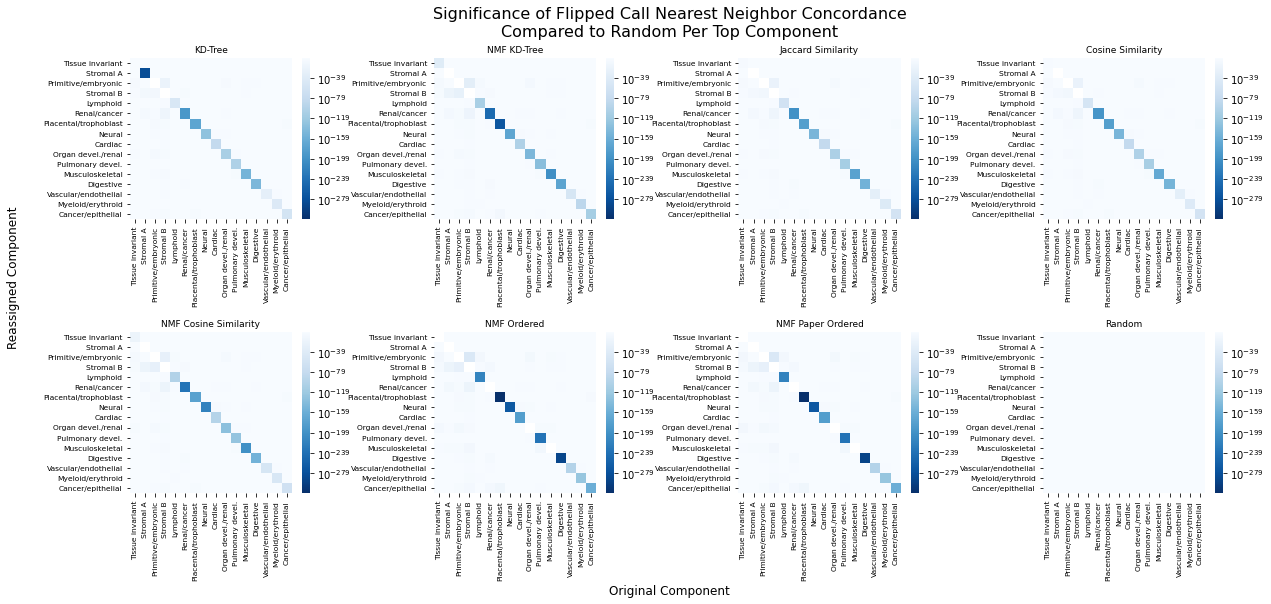

In [306]:
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(20,8))
# plt.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=0.3, hspace=None)
plt.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=0.5, hspace=0.7)
fig.patch.set_facecolor('white')
# fig.tight_layout()

comps_for_heatmap_no_spaces = ['Tissue invariant','Stromal A', 'Primitive/embryonic', 'Stromal B', 'Lymphoid', 'Renal/cancer', 'Placental/trophoblast', 'Neural', 'Cardiac', 'Organ devel./renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular/endothelial', 'Myeloid/erythroid', 'Cancer/epithelial']

axes = axes.ravel()

for ax, ind in zip(axes, range(len(axes))):
    sns.heatmap(cycle0_biosample_metric_v_random_concord_pvals_by_comp[ind], ax=ax, 
                xticklabels=comps_for_heatmap_no_spaces, yticklabels=comps_for_heatmap_no_spaces, 
                cmap='Blues_r', cbar=True, norm=LogNorm(vmin=1e-318)) # 
    ax.set_xticklabels(comps_for_heatmap_no_spaces, fontsize=7.5)
    ax.set_yticklabels(comps_for_heatmap_no_spaces, fontsize=7.5)
    ax.set_title(labels[ind], fontsize=9)
    
fig.text(0.04, 0.5, 'Reassigned Component', va='center', rotation='vertical', fontsize=12)
fig.text(0.5, -0.05, 'Original Component', ha='center', fontsize=12)
plt.suptitle('Significance of Flipped Call Nearest Neighbor Concordance\nCompared to Random Per Top Component', fontsize=16, x=0.5, y=0.97)

Text(0.5, 1.0, 'Nearest Neighbor Concordance and Total Number\nof Positive Biosamples for Flipped Calls')

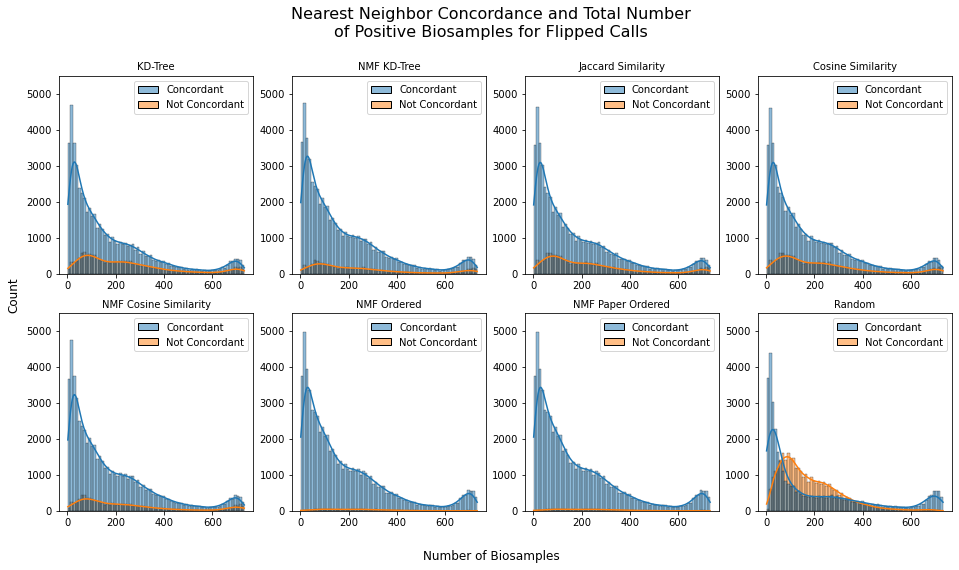

In [35]:
# fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(16,8))
# # plt.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=0.3, hspace=None)
# fig.patch.set_facecolor('white')
# # fig.tight_layout()

# axes = axes.ravel()

# for ax, result, ind in zip(axes, [cycle0_biosample_kdtree_neighbor_addedremoved_concord,
#                                   cycle0_biosample_NMF_kdtree_neighbor_addedremoved_concord,
#                                   cycle0_biosample_jsimilarity_addedremoved_concord,
#                                   cycle0_biosample_cosine_addedremoved_concord,
#                                   cycle0_biosample_NMF_cosine_addedremoved_concord,
#                                   cycle0_biosample_NMF_ordered_addedremoved_concord,
#                                   cycle0_biosample_NMF_official_ordered_addedremoved_concord,
#                                   cycle0_biosample_random_addedremoved_concord],
#                           range(len(axes))):
    
#     if result.shape == (69292, 11):
#         concord_inds = np.where(result[:, 14]==1)
#         not_concord_inds = np.where(result[:, 14]==0)
#     else:
#         concord_inds = np.where(result[:, 4]==1)
#         not_concord_inds = np.where(result[:, 4]==0)
#     concord_biosamples = result[concord_inds, 3]
#     not_concord_biosamples = result[not_concord_inds, 3]
    
# #     df1 = pd.DataFrame(np.array([concord_biosamples.flatten()]).T, 
# #                        columns=['Concordant'])
# #     df2 = pd.DataFrame(np.array([not_concord_biosamples.flatten()]).T, 
# #                        columns=['Not Concordant'])
#     df=pd.DataFrame([concord_biosamples.flatten(), not_concord_biosamples.flatten()], index=['Concordant', 'Not Concordant']).transpose()
    
#     t1 = sns.histplot(data=df, ax=ax, kde=True)
#     axes[ind].set_title(labels[ind], fontsize=10)
#     ax.set_ylabel(None)
#     ax.set_ylim([0, 5500])
# #     axes[ind+2].set_title('Cycle %s Basis' %(ind), fontsize=10)

# # axes[0].set_ylabel('Number of DHSs', fontsize=12)
# # axes[2].set_ylabel('Number of Biosamples', fontsize=12)
# fig.text(0.08, 0.5, 'Count', va='center', rotation='vertical', fontsize=12)
# fig.text(0.5, 0.04, 'Number of Biosamples', ha='center', fontsize=12)
# plt.suptitle('Nearest Neighbor Concordance and Total Number\nof Positive Biosamples for Flipped Calls', fontsize=16, x=0.5, y=1.0)